# GENESIS results
Included the reference panel samples with the E280As. \
Determine whether PC-AiR worked properly --> PCs represent ancestry not relatedness.

##### Modules

In [2]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib import font_manager

##### Fonts & Colors

In [3]:
# font style
locations = ['/home/eger/software/fonts']
font_files = font_manager.findSystemFonts(fontpaths = locations)
for file in font_files:
    font_manager.fontManager.addfont(file)
plt.rcParams['font.family'] = 'Aptos'

# font size
title_size = 24
label_size = 18
tick_size = 16

# colors
plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.tab20b.colors)
E280A_color = 'skyblue'
anc_color_dict = {'EUR': 'dodgerblue', 'AMR': 'green', 'AFR': 'purple'}

##### Inputs

In [4]:
prefix = 'hgdp_1kg.AFR_AMR_EUR_unrelated_E280A_340.auto.hg38'

DIR0 = '/scratch/eger/projects/E280A_SNP_arrays/E280A_340'
DIR1 = '/scratch/eger/projects/E280A_SNP_arrays/E280A_340/GENESIS_v2'

# fam file
fam = os.path.join(DIR0, 'merge_hgdp_1kg', prefix+'.fam')

# pcair outputs
pcs = os.path.join(DIR1, prefix+'_pcair_PCs.txt')
varprop = os.path.join(DIR1, prefix+'_pcair_varprop.txt')
rels = os.path.join(DIR1, prefix+'_pcair_rels.txt')
unrels = os.path.join(DIR1, prefix+'_pcair_unrels.txt')

# pcrelate outputs
kin = os.path.join(DIR1, prefix+'_kinship.txt')

### read in files ###
df0 = pd.read_csv(fam, sep='\s+', header=None,
                      names=['FID', 'IID', 'FA', 'MO', 'SEX', 'PHENO'])

df1 = pd.read_csv(pcs, header=None, sep='\s+')
df1.columns = ['IID'] + ['PC'+str(i) for i in np.arange(1, df1.shape[1])]
df1 = df0.merge(df1, on=['IID'], how='inner')


varprop_dict = dict(zip(['PC'+str(i) for i in np.arange(1, df1.shape[1])],
                        pd.read_csv(varprop)['varprop']))
rels_ids = list(pd.read_csv(rels, header=None)[0])
unrels_ids = list(pd.read_csv(unrels, header=None)[0])

df2 = pd.read_csv(kin, sep='\s+')

## PC-AiR

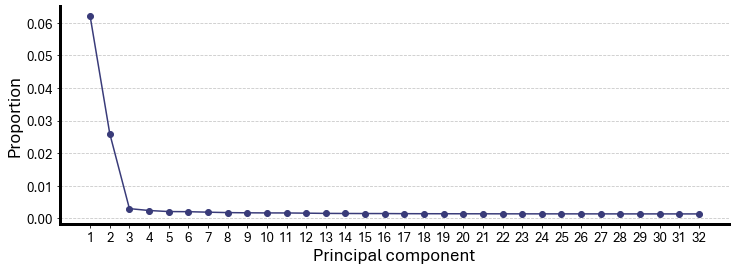

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

ax.plot(np.arange(1, len(varprop_dict)+1), varprop_dict.values(), zorder=3)
ax.scatter(np.arange(1, len(varprop_dict)+1), varprop_dict.values(), zorder=3)

#ax.set_ylim(0, 0.01)
ax.tick_params(axis='both', labelsize=14)
ax.set_xticks(np.arange(1, len(varprop_dict)+1))
ax.set_xlabel('Principal component', fontsize=18)
ax.set_ylabel('Proportion', fontsize=18)

plt.show()

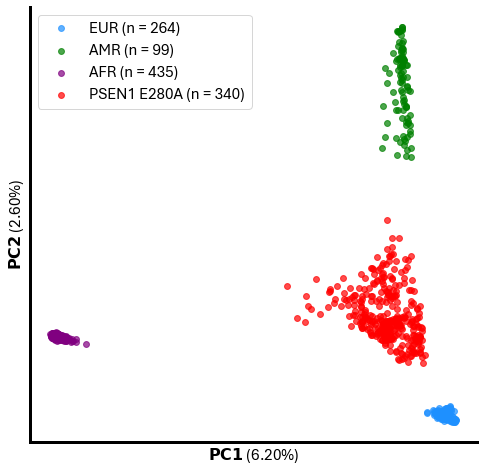

In [10]:
x_var = 'PC1'
y_var = 'PC2'

fig, ax = plt.subplots(figsize=(8, 8))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
#ax.grid(True, axis='both', linestyle='--', alpha=0.7, zorder=0)
ax.tick_params(axis='both', labelsize=14)

for pop in anc_color_dict.keys():
    ax.scatter(df1[df1['FID'] == pop][x_var], 
               df1[df1['FID'] == pop][y_var], 
               label=pop+' (n = '+str(df1[df1['FID'] == pop].shape[0])+')', 
               color=anc_color_dict[pop],
               s=35, alpha=0.7, zorder=3)    

ax.scatter(df1[~df1['FID'].isin(anc_color_dict.keys())][x_var], 
           df1[~df1['FID'].isin(anc_color_dict.keys())][y_var], 
           color='red', 
           label='PSEN1 E280A (n = '+str(df1[~df1['FID'].isin(anc_color_dict.keys())].shape[0])+')',
           s=35, alpha=0.7, zorder=3)    

#ax.set_xlim(-(df1[x_var].abs().max() + 0.1), df1[x_var].abs().max() + 0.1)
#ax.set_ylim(-(df1[y_var].abs().max() + 0.1), df1[y_var].abs().max() + 0.1)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=16)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=16)
ax.legend(loc='upper left', fontsize=16)

plt.show()

In [14]:
df3 = pd.DataFrame({'FID': df1[~df1['FID'].isin(anc_color_dict.keys())]['FID'].value_counts().index,
                    'N': df1[~df1['FID'].isin(anc_color_dict.keys())]['FID'].value_counts().values})
df3 = df3[df3['N'] > 4]

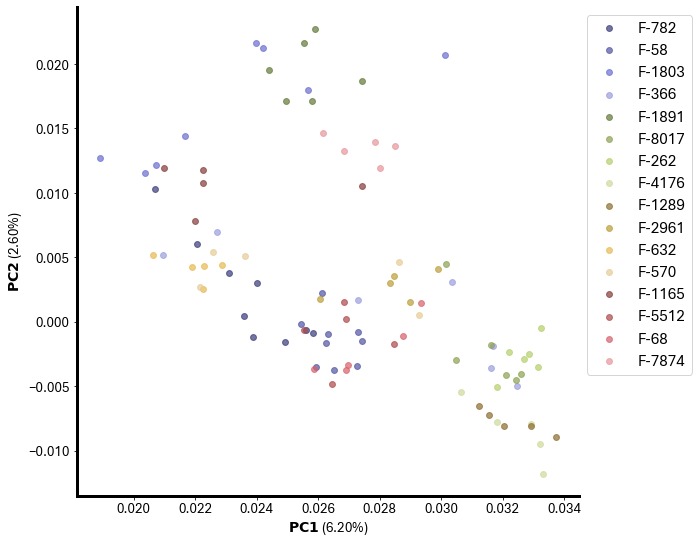

In [16]:
x_var = 'PC1'
y_var = 'PC2'

fig, ax = plt.subplots(figsize=(9, 9))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
#ax.grid(True, axis='both', linestyle='--', alpha=0.7, zorder=0)
ax.tick_params(axis='both', labelsize=14)

for i, row in df3.iterrows():
    ax.scatter(df1[df1['FID'] == row['FID']][x_var], 
               df1[df1['FID'] == row['FID']][y_var], 
               label=row['FID'],
               s=35, alpha=0.7, zorder=3)    

#ax.set_xlim(-(df1[x_var].abs().max() + 0.1), df1[x_var].abs().max() + 0.1)
#ax.set_ylim(-(df1[y_var].abs().max() + 0.1), df1[y_var].abs().max() + 0.1)
ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=14)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=14)
ax.legend(bbox_to_anchor=(1, 1), fontsize=16)

plt.show()